#Chapter04 - Building Good Training Datasets - Data Preprocessing

## Dealing with missing data

###Identifying missing values in tabular data

In [69]:
import pandas as pd
from io import StringIO
csv_data = '''A,B,C,D
              1.0, 2.0, 3.0, 4.0
              5.0, 6.0,, 8.0
              10.0, 11.0, 12.0,'''
df = pd.read_csv(StringIO(csv_data))
df

,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,NaN,8.0
2,10.0,11.0,12.0,NaN


In [70]:
df.isnull().sum()

,0
A,0
B,0
C,1
D,1


###Eliminating training examples or features with missing values

In [71]:
df.dropna()

,A,B,C,D
0,1.0,2.0,3.0,4.0


In [72]:
df.dropna(axis = 1)

,A,B
0,1.0,2.0
1,5.0,6.0
2,10.0,11.0


In [73]:
df.dropna(how = 'all')

,A,B,C,D
0,1.0,2.0,3.0,4.0
1,5.0,6.0,NaN,8.0
2,10.0,11.0,12.0,NaN


In [74]:
df.dropna(thresh = 4)

,A,B,C,D
0,1.0,2.0,3.0,4.0


In [75]:
df.dropna(subset = ['C'])

,A,B,C,D
0,1.0,2.0,3.0,4.0
2,10.0,11.0,12.0,NaN


###Imputing  missing values

In [76]:
#最頻値補完
from sklearn.impute import SimpleImputer
import numpy as np
imr = SimpleImputer(missing_values = np.nan, strategy = 'most_frequent')
imr = imr.fit(df.values)
imputed_data = imr.transform(df.values)
imputed_data

array([[ 1.,  2.,  3.,  4.],
       [ 5.,  6.,  3.,  8.],
       [10., 11., 12.,  4.]])

##Handing categorial data

###Normal ans ordinal features

In [77]:
import pandas as pd
df = pd.DataFrame([
    ['green', 'M', '10.1', 'class2'],
    ['red', 'L', '13.5', 'class1'],
    ['blue', 'XL', '15.3', 'class2']])
df.columns = ['color', 'size', 'price', 'classlabel']
df

,color,size,price,classlabel
0,green,M,10.1,class2
1,red,L,13.5,class1
2,blue,XL,15.3,class2


###Mapping ordinal features

In [78]:
size_mapping = {'XL' : 3, 'L': 2, 'M' : 1}
df['size'] = df['size'].map(size_mapping)
df

,color,size,price,classlabel
0,green,1,10.1,class2
1,red,2,13.5,class1
2,blue,3,15.3,class2


In [79]:
inv_size_mapping = {v : k for k, v in size_mapping.items()}
df['size'].map(inv_size_mapping)

,size
0,M
1,L
2,XL


###Encoding class labels

In [80]:
import numpy as np
class_mapping = {label : idx for idx, label in enumerate(np.unique(df['classlabel']))}
class_mapping

{'class1': 0, 'class2': 1}

In [81]:
df['classlabel'] = df['classlabel'].map(class_mapping)
df

,color,size,price,classlabel
0,green,1,10.1,1
1,red,2,13.5,0
2,blue,3,15.3,1


In [82]:
inv_class_mapping = {v : k for k, v in class_mapping.items()}
df['classlabel'] = df['classlabel'].map(inv_class_mapping)
df

,color,size,price,classlabel
0,green,1,10.1,class2
1,red,2,13.5,class1
2,blue,3,15.3,class2


In [83]:
from sklearn.preprocessing import LabelEncoder
class_le = LabelEncoder()
y = class_le.fit_transform(df['classlabel'].values)
y

array([1, 0, 1])

In [84]:
class_le.inverse_transform(y)

array(['class2', 'class1', 'class2'], dtype=object)

##Performing one-hot encoding on nominal features

In [102]:
X = df[['color', 'size', 'price']].values
color_le = LabelEncoder()
X[ : , 0] = color_le.fit_transform(X[ : , 0])
X

array([[1, 1, '10.1'],
       [2, 2, '13.5'],
       [0, 3, '15.3']], dtype=object)

In [86]:
from sklearn.preprocessing import OneHotEncoder
X = df[['color', 'size', 'price']].values
color_ohe = OneHotEncoder()
color_ohe.fit_transform(X[ : , 0].reshape(-1, 1)).toarray()

array([[0., 1., 0.],
       [0., 0., 1.],
       [1., 0., 0.]])

In [87]:
from sklearn.compose import ColumnTransformer
X = df[['color', 'size', 'price']].values
c_transf = ColumnTransformer([('one_hot', OneHotEncoder(), [0]),
                             ('nothing', 'passthrough', [1, 2])])
c_transf.fit_transform(X).astype(float)

array([[ 0. ,  1. ,  0. ,  1. , 10.1],
       [ 0. ,  0. ,  1. ,  2. , 13.5],
       [ 1. ,  0. ,  0. ,  3. , 15.3]])

In [88]:
pd.get_dummies(df[['price', 'color', 'size']])

,size,price_10.1,price_13.5,price_15.3,color_blue,color_green,color_red
0,1,True,False,False,False,True,False
1,2,False,True,False,False,False,True
2,3,False,False,True,True,False,False


In [89]:
pd.get_dummies(df[['price', 'color', 'size']], drop_first = True)

,size,price_13.5,price_15.3,color_green,color_red
0,1,False,False,True,False
1,2,True,False,False,True
2,3,False,True,False,False


##Partitioning a datasetes into a seperate training and test set

In [90]:
df_wine = pd.read_csv('https://archive.ics.uci.edu/'
                      'ml/machine-learning-databases/wine/wine.data',
                      header=None)
df_wine.columns = ['Class label', 'Alcohol', 'Malic acid', 'Ash',
                   'Alcalinity of ash', 'Magnesium', 'Total phenols',
                   'Flavanoids', 'Nonflavanoid phenols', 'Proanthocyanins',
                   'Color intensity', 'Hue', 'OD280/OD315 of diluted wines',
                   'Proline']
print('Class labels', np.unique(df_wine['Class label']))
df_wine.head()

Class labels [1 2 3]


,Class label,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [91]:
from sklearn.model_selection import train_test_split
X, y = df_wine.iloc[ : , 1 : ].values, df_wine.iloc[ : , 0].values
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 0, stratify = y)

##Bringing features onto the same scale

In [92]:
from sklearn.preprocessing import MinMaxScaler
mms = MinMaxScaler()
X_train_norm = mms.fit_transform(X_train)
X_test_norm = mms.transform(X_test)

In [93]:
ex = np.array([0, 1, 2, 3, 4, 5])
print('standardized : ', (ex - ex.mean()) / ex.std())
print('normarized : ', (ex - ex.min()) / (ex.max() - ex.min()))

standardized :  [-1.46385011 -0.87831007 -0.29277002  0.29277002  0.87831007  1.46385011]
normarized :  [0.  0.2 0.4 0.6 0.8 1. ]


In [94]:
from sklearn.preprocessing import StandardScaler
stdsc = StandardScaler()
X_train_std = stdsc.fit_transform(X_train)
X_test_std = stdsc.fit_transform(X_test)

## Selecting meaningful features

### Sparse solutions with L1-regularization

In [95]:
from sklearn.linear_model import LogisticRegression
LogisticRegression(penalty = 'l1',solver = 'liblinear', multi_class = 'ovr')

LogisticRegression(multi_class='ovr', penalty='l1', solver='liblinear')

In [96]:
lr = LogisticRegression(penalty = 'l1', C = 1.0, solver = 'liblinear', multi_class = 'ovr')
lr.fit(X_train_std, y_train)
print('Training Acurracy : ', lr.score(X_train_std, y_train))
print('Test Acurracy : ', lr.score(X_test_std, y_test))

Training Acurracy :  1.0
Test Acurracy :  1.0


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


In [97]:
lr.intercept_

array([-1.26349838, -1.21599293, -2.37013806])

In [98]:
lr.coef_

array([[ 1.24612854,  0.18002858,  0.74610207, -1.16346226,  0.        ,
         0.        ,  1.15901763,  0.        ,  0.        ,  0.        ,
         0.        ,  0.5571748 ,  2.5091157 ],
       [-1.53759581, -0.38692088, -0.99526234,  0.36483651, -0.05956289,
         0.        ,  0.66768907,  0.        ,  0.        , -1.93379242,
         1.23450539,  0.        , -2.23162473],
       [ 0.13585531,  0.16838194,  0.35722803,  0.        ,  0.        ,
         0.        , -2.43795724,  0.        ,  0.        ,  1.56334907,
        -0.81924322, -0.4925282 ,  0.        ]])

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was depre

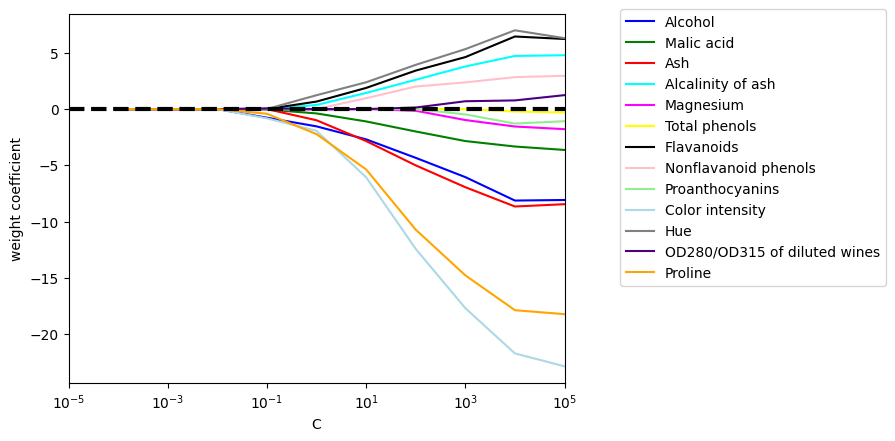

In [99]:
import matplotlib.pyplot as plt

fig = plt.figure()
ax = plt.subplot(111)
colors = ['blue', 'green', 'red', 'cyan',
          'magenta', 'yellow', 'black',
          'pink', 'lightgreen', 'lightblue',
          'gray', 'indigo', 'orange']
weights, params = [], []
for c in np.arange(-4., 6.):
    lr = LogisticRegression(penalty='l1', C=10.**c, solver='liblinear',
                            multi_class='ovr', random_state=0)
    lr.fit(X_train_std, y_train)
    weights.append(lr.coef_[1])
    params.append(10**c)

weights = np.array(weights)

for column, color in zip(range(weights.shape[1]), colors):
    plt.plot(params, weights[:, column],
             label=df_wine.columns[column + 1],
             color=color)
plt.axhline(0, color='black', linestyle='--', linewidth=3)
plt.xlim([10**(-5), 10**5])
plt.ylabel('weight coefficient')
plt.xlabel('C')
plt.xscale('log')
plt.legend(loc='upper left')
ax.legend(loc='upper center',
          bbox_to_anchor=(1.38, 1.03),
          ncol=1, fancybox=True)
plt.show()

## Assessing feature importance wifh Random Forests

 1) Proline                        0.200307
 2) Flavanoids                     0.193822
 3) Color intensity                0.125179
 4) OD280/OD315 of diluted wines   0.123562
 5) Alcohol                        0.121041
 6) Hue                            0.070303
 7) Total phenols                  0.040033
 8) Magnesium                      0.037153
 9) Proanthocyanins                0.026425
10) Alcalinity of ash              0.020495
11) Malic acid                     0.019891
12) Ash                            0.012578
13) Nonflavanoid phenols           0.009211


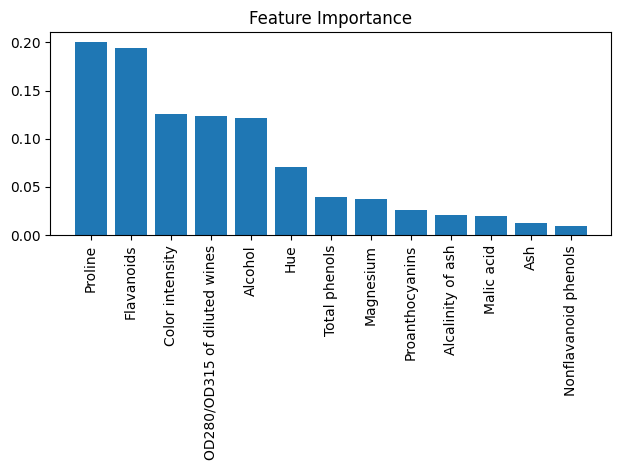

In [100]:
from sklearn.ensemble import RandomForestClassifier
feat_labels = df_wine.columns[1 : ]
forest = RandomForestClassifier(n_estimators = 100, random_state = 1)
forest.fit(X_train, y_train)
importances = forest.feature_importances_
indices = np.argsort(importances)[::-1]
for f in range(X_train.shape[1]):
    print("%2d) %-*s %f" % (f + 1, 30,
                            feat_labels[indices[f]],
                            importances[indices[f]]))
plt.title('Feature Importance')
plt.bar(range(X_train.shape[1]),
        importances[indices],
        align='center')
plt.xticks(range(X_train.shape[1]),
           feat_labels[indices], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.tight_layout()
plt.show()

In [101]:
from sklearn.feature_selection import SelectFromModel
sfm = SelectFromModel(forest, threshold = 0.1, prefit = True)
X_selected = sfm.fit_transform(X_train)
print(X_selected.shape[1])
for i in range(X_selected.shape[1]) :
  print(feat_labels[indices[i]])

5
Proline
Flavanoids
Color intensity
OD280/OD315 of diluted wines
Alcohol
